# Experiment 9: Document Ranking using TF-IDF and BM25

**Course:** Multimodal Data Analysis (BAI-417)
**Name:** Sneha Roychowdhury
**Section:** ECE-AI (2)

---

## Aim
To implement document ranking using the TF-IDF and BM25 techniques and retrieve the most relevant documents for a given search query.

## Theory

### 1. The ranked retrieval problem
A search system receives a query $q$ and a collection of documents $D = \{d_1, \dots, d_N\}$. Instead of a yes/no answer (Boolean retrieval), it gives every document a **relevance score** $s(q,d)$ and returns documents in decreasing order of score. The quality of a system therefore depends on its **scoring function**. This experiment builds two classic scoring functions, TF-IDF and BM25, from scratch.

### 2. Inverted index
Scanning every document for every query is slow. Real search engines first build an **inverted index**: for each term, a **postings list** of the documents that contain it, along with the term frequency in each.

```
"signal"   →  [(D16, 1), (D17, 3), (D18, 2), (D19, 2)]
"network"  →  [(D01, 2), (D02, 1), (D21, 2), (D27, 9), ...]
```

At query time only the postings of the query terms are read, and scores are added up per document in **accumulators** (term-at-a-time scoring).

### 3. Text preprocessing
Both models use the same pipeline: lowercase → tokenise → remove stopwords → **Porter stemming** (so *classify, classification, classifier* all become *classif*). Stemming merges word forms so that a query and a document can match even when they use different forms of a word.

### 4. TF-IDF with cosine similarity (vector space model)
Each document becomes a vector over the vocabulary:

$$w_{t,d} = \text{tf}(t,d)\times\text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1+N}{1+\text{df}(t)} + 1$$

- **tf** (term frequency): how often $t$ occurs in $d$. A *sublinear* variant uses $1+\ln(\text{tf})$ to dampen repetition.
- **idf** (inverse document frequency): rare terms are more informative than common ones.

Vectors are L2-normalised and documents are ranked by **cosine similarity** with the query vector:

$$\cos(q,d) = \frac{\vec q\cdot\vec d}{\lVert\vec q\rVert\,\lVert\vec d\rVert}$$

### 5. Okapi BM25 (probabilistic model)
BM25 comes from the probabilistic relevance framework and is the default ranking function in Lucene, Elasticsearch and Solr:

$$\text{BM25}(q,d) = \sum_{t\in q}\text{IDF}(t)\cdot\frac{\text{tf}(t,d)\,(k_1+1)}{\text{tf}(t,d)+k_1\left(1-b+b\,\frac{|d|}{\text{avgdl}}\right)}, \qquad \text{IDF}(t)=\ln\left(1+\frac{N-n_t+0.5}{n_t+0.5}\right)$$

- $k_1$ (default 1.2) sets **term-frequency saturation**: after a few occurrences, extra repetitions add very little.
- $b$ (default 0.75) sets **length normalisation**: a term found in a short, focused document counts more than the same term in a long one.

### 6. Evaluation measures
Relevance judgements (*qrels*) are **graded**: 2 = highly relevant, 1 = partially relevant, 0 = not relevant.

| Measure | What it captures |
|---|---|
| Precision@k | Share of the top k results that are relevant |
| Recall@k | Share of all relevant documents found in the top k |
| Average Precision (AP), MAP | Precision averaged at each relevant document's rank; MAP is the mean over queries |
| MRR | $1/\text{rank}$ of the first relevant result, averaged over queries |
| nDCG@k | Uses the graded labels; gain $2^{rel}-1$ discounted by $\log_2(\text{rank}+1)$, divided by the ideal ordering |

## Algorithm
1. Create the dataset (30 documents, 8 queries, graded relevance labels) and export it as text files.
2. Load the text files and preprocess every document.
3. Build an inverted index and collection statistics (N, df, document lengths, avgdl).
4. Implement TF-IDF + cosine scoring over the index; verify it against scikit-learn.
5. Implement Okapi BM25 scoring over the index; verify it against the `rank_bm25` library.
6. Retrieve the top documents for each query with both methods.
7. Evaluate with P@5, R@5, MAP, MRR and nDCG@10, plus precision-recall curves.
8. Study behaviour: keyword stuffing, document length, agreement between rankings, and BM25 parameters.
9. Build a small search interface that highlights the matched terms in the results.

## Step 0: Install and import libraries
All of these come preinstalled on Colab except `rank_bm25`, which is used only to cross-check our own BM25.

In [1]:
!pip -q install rank_bm25 2> /dev/null

import re, math, time, html
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from scipy.stats import kendalltau
from rank_bm25 import BM25Okapi
from IPython.display import HTML, display

pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.dpi"] = 110
print("Libraries loaded")

Libraries loaded


## Step 1: Create and export the dataset
The corpus is a small **AI and ECE knowledge base** of 30 short articles covering machine learning, deep learning, signal processing, communication and embedded systems. Each line of `kb_documents.txt` has the form `DOC_ID | TITLE | TEXT`.

A few documents are included on purpose to test the ranking models:
- **D27** is a keyword-stuffed promotional page that repeats *"neural network"* many times but teaches nothing.
- **D28** is a long survey that mentions many topics briefly, so it matches many queries a little.
- Some queries use different words from the relevant documents (for example *"sequence models"* vs *"recurrent"*), which tests the limits of word matching.

Relevance labels are stored in `kb_qrels.txt` in the standard **TREC format** (`query_id  0  doc_id  relevance`), which is how evaluation datasets such as MS MARCO and TREC are distributed.

In [2]:
documents_txt = """D01 | Convolutional neural networks for image classification | A convolutional neural network (CNN) learns image features with small filters that slide across the image. Convolution layers detect edges and textures, pooling layers reduce the spatial size, and fully connected layers perform the final image classification. CNNs such as LeNet and VGG classify handwritten digits and natural images with high accuracy.
D02 | Recurrent neural networks and LSTM | Recurrent neural networks process sequential data one step at a time while keeping a hidden state. Long short-term memory (LSTM) and GRU cells use gates to remember long-range dependencies and reduce the vanishing gradient problem. They are used for language modelling, speech recognition and time series forecasting.
D03 | Transformers and self-attention | The transformer architecture replaces recurrence with self-attention, letting every token attend to every other token in parallel. Positional encoding adds word order information. Transformers power machine translation, text summarisation and models such as BERT and GPT.
D04 | Overfitting, dropout and regularisation | Overfitting happens when a model memorises the training data and fails on unseen data. Common remedies are L1 and L2 regularisation, dropout, which randomly switches off neurons during training, early stopping on a validation set, and collecting more data. Regularisation keeps weights small and improves generalisation.
D05 | Gradient descent and optimisers | Neural network training minimises a loss function with gradient descent. Stochastic gradient descent updates weights using mini-batches, momentum smooths the updates, and adaptive optimisers such as RMSProp and Adam scale the learning rate for each parameter. Choosing the learning rate and the optimiser strongly affects training speed.
D06 | Data augmentation for images | Data augmentation creates new training images by flipping, rotating, cropping, scaling and changing brightness. It increases the variety of the training set, reduces overfitting and helps image classifiers generalise when labelled data is limited.
D07 | Transfer learning with pretrained models | Transfer learning reuses a model pretrained on a large dataset such as ImageNet. Networks like ResNet are fine-tuned on a smaller target dataset by retraining only the last layers, which saves time and works well for image classification with few labelled examples.
D08 | Decision trees and random forests | A decision tree splits data on feature thresholds chosen by Gini impurity or information gain. A random forest trains many trees on bootstrapped samples and random feature subsets, then combines their votes, which lowers variance and improves accuracy on tabular data.
D09 | Support vector machines | A support vector machine finds the hyperplane that separates two classes with the maximum margin. Kernel functions such as the RBF kernel map data into higher dimensions so that SVMs can learn non-linear decision boundaries.
D10 | K-means clustering | K-means is an unsupervised learning algorithm that groups unlabelled data into k clusters. It alternates between assigning points to the nearest centroid and recomputing centroids. The elbow method and silhouette score help choose the number of clusters.
D11 | Principal component analysis | Principal component analysis (PCA) is an unsupervised dimensionality reduction technique. It projects data onto orthogonal directions of maximum variance, the principal components, using the eigenvectors of the covariance matrix. PCA is used for compression, visualisation and noise removal.
D12 | Classification evaluation metrics | Accuracy can mislead on imbalanced data, so classifiers are also judged by precision, recall and the F1 score. A confusion matrix counts true and false positives and negatives, and the ROC curve with its AUC shows the trade-off across thresholds.
D13 | Inverted index in search engines | A search engine builds an inverted index that maps every term to a postings list of the documents containing it. At query time only the postings of the query terms are read, so ranking millions of documents takes milliseconds. Compression of postings lists saves memory.
D14 | TF-IDF term weighting | TF-IDF weights a term by its frequency in a document multiplied by its inverse document frequency across the collection. Rare terms receive high weight and common words receive low weight. Documents are ranked against a query using cosine similarity between TF-IDF vectors.
D15 | Word embeddings and Word2Vec | Word embeddings represent words as dense vectors so that similar words lie close together. Word2Vec learns them with the skip-gram or CBOW objective, and GloVe uses global co-occurrence counts. Embeddings capture analogies such as king minus man plus woman equals queen.
D16 | Speech recognition with MFCC features | Automatic speech recognition converts spoken audio into text. The audio signal is split into short frames and mel frequency cepstral coefficients (MFCC) are extracted from each frame's spectrum. Acoustic models, once HMMs and now deep networks, map these features to phonemes and words.
D17 | Fourier transform and frequency spectrum | The Fourier transform decomposes a signal into sinusoids of different frequencies. The discrete Fourier transform, computed efficiently with the FFT, gives the frequency spectrum of a sampled signal, showing the magnitude and phase of each frequency component.
D18 | Digital filters: FIR and IIR | Digital filters remove unwanted frequency components from a signal. FIR filters have a finite impulse response and linear phase, while IIR filters use feedback and need fewer coefficients. Low-pass, high-pass and band-pass filters are designed from their frequency response.
D19 | Sampling theorem and aliasing | The Nyquist sampling theorem states that a signal must be sampled at more than twice its highest frequency to be reconstructed without loss. Sampling too slowly causes aliasing, where high frequency components appear as false low frequencies, so an anti-aliasing filter is applied first.
D20 | Amplitude and frequency modulation | Modulation places a message onto a high frequency carrier for transmission. Amplitude modulation varies the carrier amplitude, while frequency modulation varies the carrier frequency and is more robust to noise. Radio broadcasting uses AM and FM, and digital systems use ASK, FSK and PSK.
D21 | 5G wireless communication | 5G wireless networks use OFDM, massive MIMO antennas and millimetre wave bands to deliver high data rates and low latency. Network slicing lets one physical network serve mobile broadband, IoT devices and critical communication with different guarantees.
D22 | Microcontrollers and embedded systems | A microcontroller combines a processor, memory and input-output peripherals on one chip. Embedded systems built on boards such as Arduino and STM32 read sensors, control motors and communicate over UART, SPI and I2C while running on very little power.
D23 | IoT and edge computing | The Internet of Things connects sensors and devices to the cloud. Edge computing processes data close to the devices, on gateways or low power boards, which reduces latency and bandwidth and keeps working when the connection drops.
D24 | Reinforcement learning and Q-learning | In reinforcement learning an agent interacts with an environment and learns a policy that maximises cumulative reward. Q-learning estimates the value of each action in each state, and deep Q-networks use neural networks to approximate these values for games and robotics.
D25 | Generative adversarial networks | A generative adversarial network trains two neural networks against each other: a generator creates fake images and a discriminator tries to tell them apart from real ones. GANs generate realistic faces, perform style transfer and create synthetic training data.
D26 | Object detection with YOLO | Object detection locates and classifies multiple objects in an image with bounding boxes. YOLO divides the image into a grid and predicts boxes and class probabilities in a single pass of a convolutional network, making it fast enough for real-time video.
D27 | Best neural network course online | Neural network neural network neural network! Join the best neural network course and master neural network skills. Our neural network bootcamp makes you a neural network expert. Neural network jobs pay well, so enrol in our neural network program today. Limited seats, best price, neural network certificate included.
D28 | A survey of deep learning | Deep learning has transformed many fields over the last decade. Convolutional networks advanced image classification and object detection, while recurrent networks and later transformers improved speech recognition, translation and text generation. Generative adversarial networks and diffusion models now create images, and reinforcement learning combined with deep networks has mastered games. Training these models relies on large datasets, GPUs, careful optimisation with methods such as Adam, and regularisation techniques such as dropout to limit overfitting. Open challenges include interpretability, robustness to adversarial examples, energy consumption, fairness and the cost of labelling data. This survey summarises the main architectures, applications and research directions, and points readers to further references in each area.
D29 | Recommendation systems | Recommendation systems suggest items a user is likely to like. Collaborative filtering uses the ratings of similar users, content-based filtering uses item features, and matrix factorisation learns latent factors for users and items. Platforms for movies, shopping and travel rely on them.
D30 | Fine-tuning large language models | Large language models are transformers pretrained on huge text corpora and then fine-tuned for specific tasks. Instruction tuning and reinforcement learning from human feedback align them with user intent, and parameter-efficient methods such as LoRA reduce the cost of fine-tuning."""

queries_txt = """Q1 | convolutional neural network for image classification
Q2 | sequence models for text and speech
Q3 | how to prevent overfitting in deep learning
Q4 | search engine ranking with inverted index and tf-idf
Q5 | frequency spectrum of a signal
Q6 | wireless communication and modulation
Q7 | unsupervised clustering and dimensionality reduction
Q8 | neural network training optimiser"""

# TREC qrels format: query_id  iteration(0)  doc_id  relevance (2 = high, 1 = partial)
qrels_txt = """Q1 0 D01 2
Q1 0 D07 1
Q1 0 D06 1
Q1 0 D26 1
Q1 0 D28 1
Q2 0 D02 2
Q2 0 D03 2
Q2 0 D16 1
Q2 0 D28 1
Q3 0 D04 2
Q3 0 D06 1
Q3 0 D28 1
Q4 0 D13 2
Q4 0 D14 2
Q5 0 D17 2
Q5 0 D19 1
Q5 0 D18 1
Q5 0 D16 1
Q6 0 D20 2
Q6 0 D21 2
Q7 0 D10 2
Q7 0 D11 2
Q8 0 D05 2
Q8 0 D04 1
Q8 0 D28 1"""

for name, content in [("kb_documents.txt", documents_txt), ("kb_queries.txt", queries_txt), ("kb_qrels.txt", qrels_txt)]:
    with open(name, "w", encoding="utf-8") as f:
        f.write(content)
    print(f"Exported {name:<18} ({len(content.splitlines())} lines)")

Exported kb_documents.txt   (30 lines)
Exported kb_queries.txt     (8 lines)
Exported kb_qrels.txt       (25 lines)


## Step 2: Load the dataset from the text files

In [3]:
docs = pd.DataFrame([dict(zip(["doc_id", "title", "text"], [p.strip() for p in line.split("|", 2)]))
                     for line in open("kb_documents.txt", encoding="utf-8") if line.strip()])
queries = pd.DataFrame([dict(zip(["qid", "query"], [p.strip() for p in line.split("|", 1)]))
                        for line in open("kb_queries.txt", encoding="utf-8") if line.strip()])

qrels = defaultdict(dict)
for line in open("kb_qrels.txt", encoding="utf-8"):
    qid, _, did, rel = line.split()
    qrels[qid][did] = int(rel)

docs["n_words"] = docs.text.str.split().str.len()
print(f"{len(docs)} documents | {len(queries)} queries | {sum(len(v) for v in qrels.values())} relevance judgements")
print(f"Document length: min {docs.n_words.min()}, mean {docs.n_words.mean():.1f}, max {docs.n_words.max()} words")
docs[["doc_id", "title", "n_words"]]

30 documents | 8 queries | 25 relevance judgements
Document length: min 34, mean 43.5, max 110 words


,doc_id,title,n_words
0,D01,Convolutional neural networks for image classification,52
1,D02,Recurrent neural networks and LSTM,47
2,D03,Transformers and self-attention,36
3,D04,"Overfitting, dropout and regularisation",46
4,D05,Gradient descent and optimisers,47
5,D06,Data augmentation for images,34
6,D07,Transfer learning with pretrained models,42
7,D08,Decision trees and random forests,41
8,D09,Support vector machines,35
9,D10,K-means clustering,37


In [4]:
queries["relevant (grade)"] = queries.qid.map(lambda q: ", ".join(f"{d}({g})" for d, g in qrels[q].items()))
queries

,qid,query,relevant (grade)
0,Q1,convolutional neural network for image classification,"D01(2), D07(1), D06(1), D26(1), D28(1)"
1,Q2,sequence models for text and speech,"D02(2), D03(2), D16(1), D28(1)"
2,Q3,how to prevent overfitting in deep learning,"D04(2), D06(1), D28(1)"
3,Q4,search engine ranking with inverted index and tf-idf,"D13(2), D14(2)"
4,Q5,frequency spectrum of a signal,"D17(2), D19(1), D18(1), D16(1)"
5,Q6,wireless communication and modulation,"D20(2), D21(2)"
6,Q7,unsupervised clustering and dimensionality reduction,"D10(2), D11(2)"
7,Q8,neural network training optimiser,"D05(2), D04(1), D28(1)"


## Step 3: Preprocessing
Lowercase, keep alphanumeric tokens, drop scikit-learn's 318 English stopwords and single characters, then apply the Porter stemmer.

In [5]:
stemmer = PorterStemmer()
STOP = set(ENGLISH_STOP_WORDS)

def preprocess(text):
    tokens = re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", text.lower())
    return [stemmer.stem(t) for t in tokens if t not in STOP and len(t) > 1]

docs["tokens"] = docs.text.apply(preprocess)
docs["length"] = docs.tokens.str.len()

example = docs.text[0][:120]
print("Raw      :", example)
print("Processed:", preprocess(example))

Raw      : A convolutional neural network (CNN) learns image features with small filters that slide across the image. Convolution l
Processed: ['convolut', 'neural', 'network', 'cnn', 'learn', 'imag', 'featur', 'small', 'filter', 'slide', 'imag', 'convolut']


## Step 4: Build the inverted index
For every stemmed term we store its postings list `{doc_index: term_frequency}`. We also keep the collection statistics both models need: N, document frequency (df), document lengths and the average document length.

In [6]:
index = defaultdict(dict)               # term -> {doc_idx: tf}
for i, toks in enumerate(docs.tokens):
    for term, tf in Counter(toks).items():
        index[term][i] = tf

N = len(docs)
doc_len = docs.length.values
avgdl = doc_len.mean()
df = {t: len(p) for t, p in index.items()}

print(f"Vocabulary size : {len(index)} terms")
print(f"Total postings  : {sum(df.values())}")
print(f"N = {N}, avgdl = {avgdl:.2f} tokens")

def show_postings(term):
    t = stemmer.stem(term)
    plist = sorted(index.get(t, {}).items())
    return f"{term!r} -> stem {t!r}, df = {len(plist)}: " + ", ".join(f"{docs.doc_id[i]}:{tf}" for i, tf in plist)

for w in ["signal", "network", "overfitting", "frequency"]:
    print(show_postings(w))

Vocabulary size : 501 terms
Total postings  : 746
N = 30, avgdl = 29.20 tokens
'signal' -> stem 'signal', df = 4: D16:1, D17:2, D18:1, D19:1
'network' -> stem 'network', df = 11: D01:1, D02:1, D05:1, D07:1, D16:1, D21:3, D24:1, D25:2, D26:1, D27:10, D28:4
'overfitting' -> stem 'overfit', df = 3: D04:1, D06:1, D28:1
'frequency' -> stem 'frequenc', df = 6: D14:2, D16:1, D17:3, D18:2, D19:3, D20:3


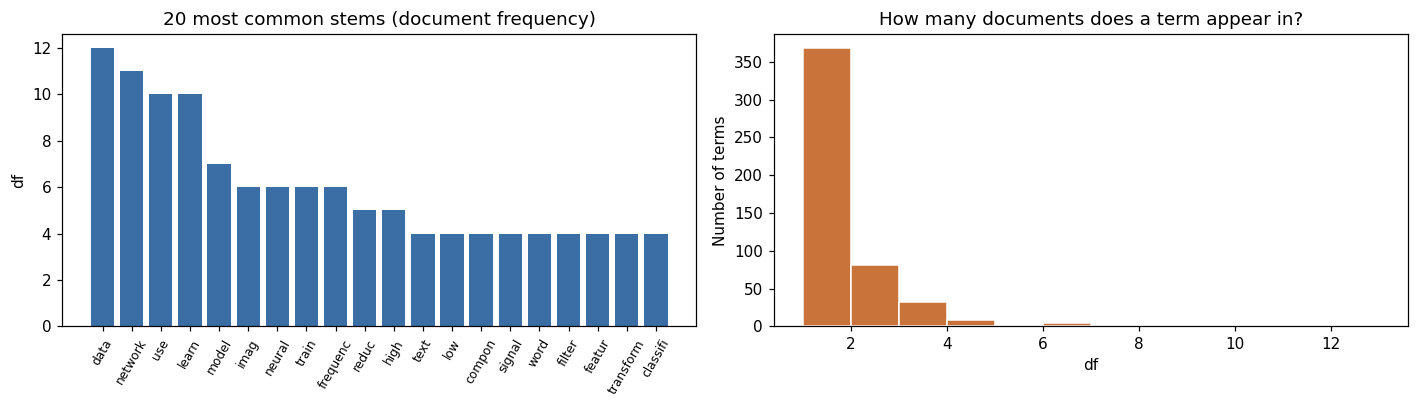

73% of terms appear in only one document


In [7]:
# Document frequency distribution: most terms are rare, a few are very common (Zipf-like)
dfs = pd.Series(df).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(range(20), dfs.values[:20], color="#3b6ea5")
axes[0].set_xticks(range(20)); axes[0].set_xticklabels(dfs.index[:20], rotation=60, fontsize=8)
axes[0].set_title("20 most common stems (document frequency)")
axes[0].set_ylabel("df")
axes[1].hist(dfs.values, bins=range(1, dfs.max() + 2), color="#c9733a", edgecolor="white")
axes[1].set_title("How many documents does a term appear in?")
axes[1].set_xlabel("df"); axes[1].set_ylabel("Number of terms")
plt.tight_layout(); plt.show()
print(f"{(dfs == 1).mean():.0%} of terms appear in only one document")

## Step 5: TF-IDF ranking, implemented over the inverted index
Document vector norms are computed once at indexing time. At query time we only walk the postings of the query terms and add $w_{t,q}\cdot w_{t,d}$ into a per-document accumulator, then divide by the norms. Two TF variants are supported:
- `raw`: tf as it is (classic TF-IDF)
- `log`: $1 + \ln(\text{tf})$ (sublinear TF, which dampens repetition)

In [8]:
class TFIDFRanker:
    def __init__(self, index, N, tf_mode="raw"):
        self.index, self.N, self.tf_mode = index, N, tf_mode
        self.idf = {t: math.log((1 + N) / (1 + len(p))) + 1 for t, p in index.items()}
        sq = np.zeros(N)
        for t, plist in index.items():
            for i, tf in plist.items():
                sq[i] += (self._tf(tf) * self.idf[t]) ** 2
        self.norm = np.sqrt(sq)

    def _tf(self, tf):
        return 1 + math.log(tf) if self.tf_mode == "log" else tf

    def score(self, query):
        q = Counter(t for t in preprocess(query) if t in self.index)
        q_w = {t: self._tf(c) * self.idf[t] for t, c in q.items()}
        q_norm = math.sqrt(sum(w * w for w in q_w.values())) or 1.0
        acc = np.zeros(self.N)
        for t, wq in q_w.items():                     # term-at-a-time
            for i, tf in self.index[t].items():
                acc[i] += wq * self._tf(tf) * self.idf[t]
        return acc / (self.norm * q_norm)

tfidf = TFIDFRanker(index, N, "raw")
tfidf_log = TFIDFRanker(index, N, "log")

# Verification against scikit-learn using the same tokens and the same settings
sk = TfidfVectorizer(analyzer=lambda x: x)            # smooth idf, raw tf, L2 norm (defaults)
D = sk.fit_transform(docs.tokens)
sk_scores = (sk.transform([preprocess(queries['query'][0])]) @ D.T).toarray().ravel()
print("Max |our TF-IDF - sklearn| :", np.abs(tfidf.score(queries['query'][0]) - sk_scores).max())

sk_log = TfidfVectorizer(analyzer=lambda x: x, sublinear_tf=True)
D2 = sk_log.fit_transform(docs.tokens)
sk2 = (sk_log.transform([preprocess(queries['query'][0])]) @ D2.T).toarray().ravel()
print("Max |our log-TF-IDF - sklearn sublinear_tf| :", np.abs(tfidf_log.score(queries['query'][0]) - sk2).max())

Max |our TF-IDF - sklearn| : 5.551115123125783e-17
Max |our log-TF-IDF - sklearn sublinear_tf| : 5.551115123125783e-17


## Step 6: BM25 ranking, implemented over the inverted index
The same index is used. The length-normalisation part depends only on the document, so it is precomputed once. Defaults are the Lucene/Elasticsearch values $k_1=1.2$, $b=0.75$.

In [9]:
class BM25Ranker:
    def __init__(self, index, doc_len, k1=1.2, b=0.75):
        self.index, self.k1, self.b = index, k1, b
        self.N = len(doc_len)
        self.avgdl = doc_len.mean()
        self.idf = {t: math.log(1 + (self.N - len(p) + 0.5) / (len(p) + 0.5)) for t, p in index.items()}
        self.K = k1 * (1 - b + b * doc_len / self.avgdl)        # per-document constant

    def score(self, query):
        acc = np.zeros(self.N)
        for t in set(preprocess(query)):
            if t not in self.index:
                continue
            for i, tf in self.index[t].items():
                acc[i] += self.idf[t] * tf * (self.k1 + 1) / (tf + self.K[i])
        return acc

bm25 = BM25Ranker(index, doc_len)

# Verification against rank_bm25. Its default IDF has no "+1" inside the log and floors
# negative values, so we hand it our IDF and compare the rest of the formula.
ref = BM25Okapi(docs.tokens.tolist(), k1=1.2, b=0.75)
ref.idf = bm25.idf
q0 = queries['query'][0]
print("Max |our BM25 - rank_bm25| :", np.abs(bm25.score(q0) - ref.get_scores(list(set(preprocess(q0))))).max())

Max |our BM25 - rank_bm25| : 8.881784197001252e-16


### 6.1 Inside a BM25 score
For one query and one document, the table breaks the score into each query term's contribution so every part of the formula is visible.

In [10]:
def explain_bm25(query, doc_id, model=bm25):
    i = docs.index[docs.doc_id == doc_id][0]
    rows = []
    for t in sorted(set(preprocess(query))):
        tf = model.index.get(t, {}).get(i, 0)
        idf = model.idf.get(t, 0.0)
        contrib = idf * tf * (model.k1 + 1) / (tf + model.K[i]) if tf else 0.0
        rows.append({"term (stem)": t, "df": len(model.index.get(t, {})), "IDF": idf, "tf in doc": tf,
                     "|d| / avgdl": doc_len[i] / model.avgdl, "contribution": contrib})
    out = pd.DataFrame(rows).round(3)
    print(f"Query: {query!r}  |  Document: {doc_id}  |  Total BM25 = {out.contribution.sum():.3f}")
    return out

explain_bm25(queries['query'][0], "D01")

Query: 'convolutional neural network for image classification'  |  Document: D01  |  Total BM25 = 9.494


,term (stem),df,IDF,tf in doc,|d| / avgdl,contribution
0,classif,3,2.181,1,1.301,1.942
1,convolut,3,2.181,2,1.301,2.765
2,imag,6,1.562,4,1.301,2.513
3,network,11,0.992,1,1.301,0.883
4,neural,6,1.562,1,1.301,1.391


## Step 7: Retrieve the most relevant documents
Top 5 results per query. The number in brackets is the relevance grade from the qrels (2 = high, 1 = partial); a dash means not relevant. Empty rows mean fewer than 5 documents share any word with the query.

In [11]:
SYSTEMS = {"TF-IDF": tfidf, "TF-IDF (log tf)": tfidf_log, "BM25": bm25}

def ranking(model, query):
    s = model.score(query)
    order = np.lexsort((np.arange(N), -s))          # sort by score, ties by doc order
    return docs.doc_id.values[order], s[order]

def top_k_table(qid, k=5):
    q = queries.set_index("qid").loc[qid, "query"]
    cols = {}
    for name in ["TF-IDF", "BM25"]:
        ids, sc = ranking(SYSTEMS[name], q)
        # a document with score 0 shares no term with the query, so it is not really "retrieved"
        cols[f"{name} doc"] = [f"{d} ({qrels[qid].get(d, '-')})" if s > 0 else "" for d, s in zip(ids[:k], sc[:k])]
        cols[f"{name} score"] = [round(s, 3) if s > 0 else "" for s in sc[:k]]
    t = pd.DataFrame(cols); t.index = range(1, k + 1)
    return q, t

for qid in queries.qid:
    q, t = top_k_table(qid)
    print(f"\n{qid}: {q!r}")
    display(t)


Q1: 'convolutional neural network for image classification'


,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
1,D27 (-),0.474,D01 (2),9.493
2,D01 (2),0.441,D26 (1),5.610
3,D28 (1),0.257,D28 (1),5.468
4,D26 (1),0.230,D07 (1),5.107
5,D07 (1),0.197,D27 (-),4.885



Q2: 'sequence models for text and speech'


,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
1,D16 (1),0.244,D16 (1),5.546
2,D28 (1),0.195,D28 (1),3.858
3,D30 (-),0.160,D03 (2),3.558
4,D02 (2),0.157,D30 (-),3.506
5,D03 (2),0.155,D02 (2),3.373



Q3: 'how to prevent overfitting in deep learning'


,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
1,D28 (1),0.249,D28 (1),4.443
2,D24 (-),0.210,D24 (-),3.920
3,D06 (1),0.115,D06 (1),2.318
4,D16 (-),0.099,D16 (-),2.187
5,D04 (2),0.098,D04 (2),2.128


... (6 outputs left out)


Q7: 'unsupervised clustering and dimensionality reduction'


,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
1,D10 (2),0.292,D11 (2),8.977
2,D11 (2),0.277,D10 (2),7.186
3,,,,
4,,,,
5,,,,



Q8: 'neural network training optimiser'


,TF-IDF doc,TF-IDF score,BM25 doc,BM25 score
1,D27 (-),0.534,D05 (2),7.755
2,D05 (2),0.377,D25 (-),5.199
3,D25 (-),0.252,D27 (-),4.885
4,D28 (1),0.204,D28 (1),3.805
5,D06 (-),0.140,D24 (-),2.754


## Step 8: Evaluation
Each system's full ranking is evaluated for every query. AP, MRR, P@5 and R@5 treat grade ≥ 1 as relevant. nDCG@10 uses the grades directly.

In [12]:
def precision_at(ids, rel, k): return sum(rel.get(d, 0) > 0 for d in ids[:k]) / k
def recall_at(ids, rel, k):    return sum(rel.get(d, 0) > 0 for d in ids[:k]) / sum(g > 0 for g in rel.values())

def average_precision(ids, rel):
    hits, total = 0, 0.0
    for r, d in enumerate(ids, 1):
        if rel.get(d, 0) > 0:
            hits += 1; total += hits / r
    return total / sum(g > 0 for g in rel.values())

def reciprocal_rank(ids, rel):
    return next((1 / r for r, d in enumerate(ids, 1) if rel.get(d, 0) > 0), 0.0)

def ndcg_at(ids, rel, k=10):
    dcg = sum((2 ** rel.get(d, 0) - 1) / math.log2(r + 1) for r, d in enumerate(ids[:k], 1))
    ideal = sorted(rel.values(), reverse=True)[:k]
    idcg = sum((2 ** g - 1) / math.log2(r + 1) for r, g in enumerate(ideal, 1))
    return dcg / idcg

rows = []
for name, model in SYSTEMS.items():
    for _, r in queries.iterrows():
        ids, _ = ranking(model, r["query"])
        rel = qrels[r.qid]
        rows.append({"system": name, "qid": r.qid, "P@5": precision_at(ids, rel, 5), "R@5": recall_at(ids, rel, 5),
                     "AP": average_precision(ids, rel), "RR": reciprocal_rank(ids, rel), "nDCG@10": ndcg_at(ids, rel)})
ev = pd.DataFrame(rows)

summary = (ev.groupby("system")[["P@5", "R@5", "AP", "RR", "nDCG@10"]].mean()
             .rename(columns={"AP": "MAP", "RR": "MRR"}).loc[list(SYSTEMS)].round(3))
summary

,P@5,R@5,MAP,MRR,nDCG@10
system,,,,,
TF-IDF,0.575,0.933,0.854,0.875,0.839
TF-IDF (log tf),0.575,0.933,0.884,1.000,0.900
BM25,0.575,0.933,0.902,1.000,0.908


In [13]:
per_q = ev.pivot(index="qid", columns="system", values="AP")[list(SYSTEMS)].round(3)
per_q["BM25 - TF-IDF"] = (per_q["BM25"] - per_q["TF-IDF"]).round(3)
per_q

system,TF-IDF,TF-IDF (log tf),BM25,BM25 - TF-IDF
qid,,,,
Q1,0.686,0.786,0.900,0.214
Q2,0.888,0.888,0.950,0.062
Q3,0.756,0.756,0.756,0.000
Q4,1.000,1.000,1.000,0.000
Q5,1.000,1.000,1.000,0.000
Q6,1.000,1.000,1.000,0.000
Q7,1.000,1.000,1.000,0.000
Q8,0.500,0.643,0.611,0.111


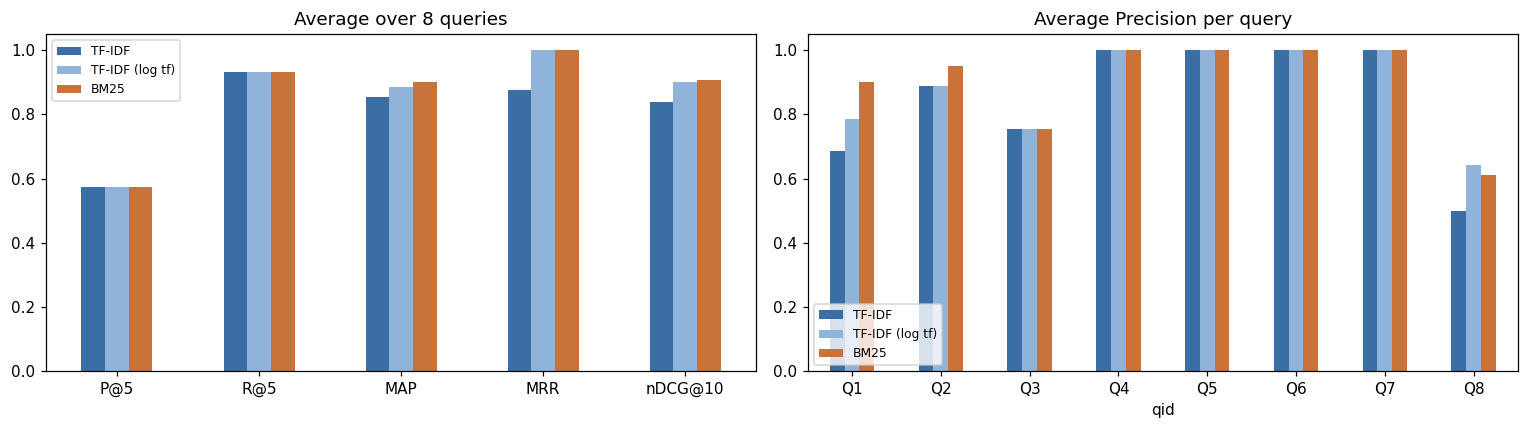

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = ["#3b6ea5", "#8fb3d9", "#c9733a"]
summary.T.plot(kind="bar", ax=axes[0], color=colors, rot=0)
axes[0].set_ylim(0, 1.05); axes[0].set_title("Average over 8 queries"); axes[0].legend(fontsize=8)

ev.pivot(index="qid", columns="system", values="AP")[list(SYSTEMS)].plot(kind="bar", ax=axes[1], color=colors, rot=0)
axes[1].set_ylim(0, 1.05); axes[1].set_title("Average Precision per query"); axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

### 8.1 Precision-recall curves
11-point interpolated precision (the highest precision at any recall level at or above each point), averaged over all queries.

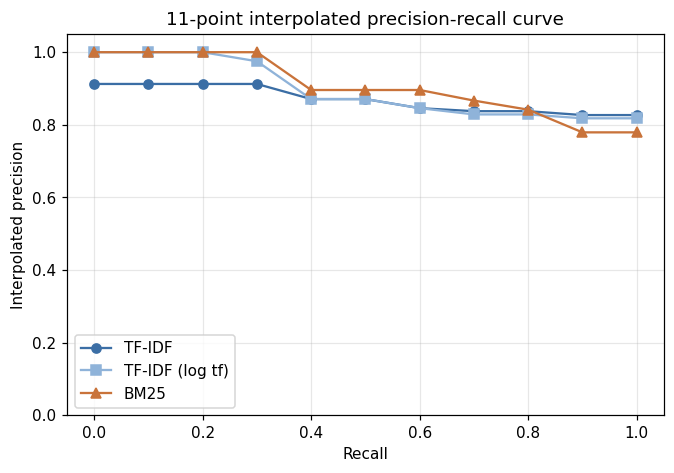

In [15]:
recall_levels = np.linspace(0, 1, 11)

def interpolated_pr(ids, rel):
    n_rel = sum(g > 0 for g in rel.values())
    prec, rec, hits = [], [], 0
    for r, d in enumerate(ids, 1):
        hits += rel.get(d, 0) > 0
        prec.append(hits / r); rec.append(hits / n_rel)
    prec, rec = np.array(prec), np.array(rec)
    return np.array([prec[rec >= L].max() if (rec >= L).any() else 0 for L in recall_levels])

plt.figure(figsize=(7, 4.5))
for (name, model), c, m in zip(SYSTEMS.items(), colors, ["o", "s", "^"]):
    curve = np.mean([interpolated_pr(ranking(model, r["query"])[0], qrels[r.qid]) for _, r in queries.iterrows()], axis=0)
    plt.plot(recall_levels, curve, marker=m, color=c, label=name)
plt.xlabel("Recall"); plt.ylabel("Interpolated precision"); plt.ylim(0, 1.05)
plt.title("11-point interpolated precision-recall curve")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Step 9: Understanding the behaviour of each model
### 9.1 Keyword stuffing (D27)
Q8 is *"neural network training optimiser"*. D27 is a promotional page that repeats *neural network* again and again. Where does each model place it?

In [16]:
q8 = queries.set_index("qid").loc["Q8", "query"]
rank_of = lambda name, did: int(np.where(ranking(SYSTEMS[name], q8)[0] == did)[0][0]) + 1
pd.DataFrame({name: {d: rank_of(name, d) for d in ["D05", "D04", "D28", "D27"]} for name in SYSTEMS},
             ).rename_axis("doc (Q8 rank)")

,TF-IDF,TF-IDF (log tf),BM25
doc (Q8 rank),,,
D05,2,1,1
D04,6,7,9
D28,4,4,4
D27,1,2,3


In [17]:
display(explain_bm25(q8, "D27"))
display(explain_bm25(q8, "D05"))

Query: 'neural network training optimiser'  |  Document: D27  |  Total BM25 = 4.885


,term (stem),df,IDF,tf in doc,|d| / avgdl,contribution
0,network,11,0.992,10,1.336,1.897
1,neural,6,1.562,10,1.336,2.988
2,optimis,2,2.518,0,1.336,0.000
3,train,6,1.562,0,1.336,0.000


Query: 'neural network training optimiser'  |  Document: D05  |  Total BM25 = 7.755


,term (stem),df,IDF,tf in doc,|d| / avgdl,contribution
0,network,11,0.992,1,1.164,0.929
1,neural,6,1.562,1,1.164,1.464
2,optimis,2,2.518,2,1.164,3.309
3,train,6,1.562,2,1.164,2.053


### 9.2 Controlled repetition test
To isolate the effect of repetition, we take a normal relevant document (D05) and append the word *"network"* to it $n$ times, then score this modified copy for Q8. The collection statistics (idf, avgdl) are kept fixed so that only the document changes.

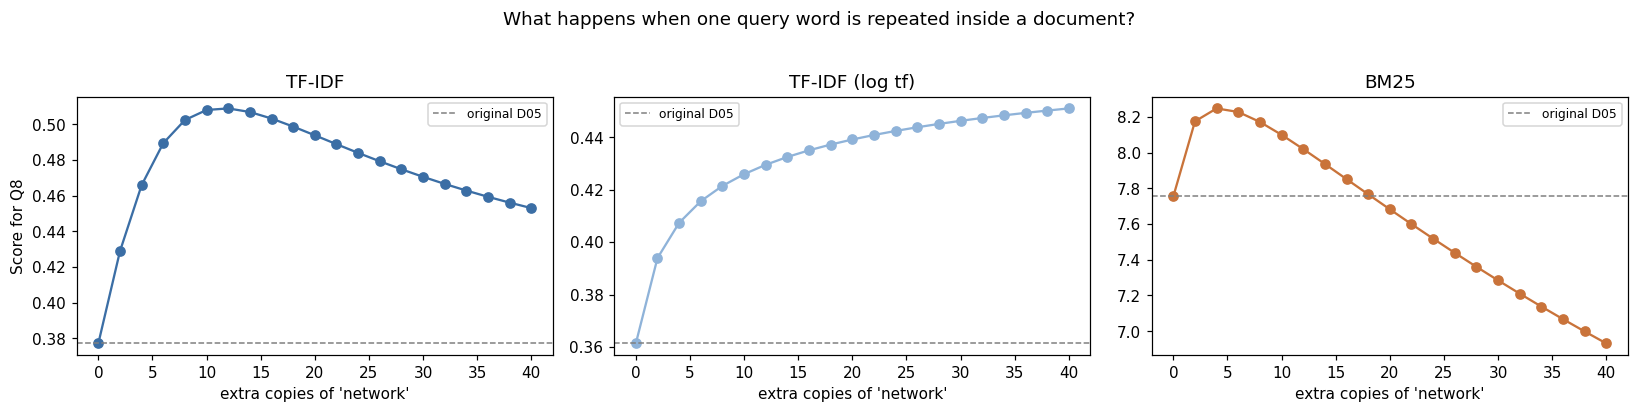

In [18]:
def score_single(tokens, query, model):
    tf = Counter(tokens)
    q_terms = [t for t in preprocess(query) if t in model.index]
    if isinstance(model, BM25Ranker):
        K = model.k1 * (1 - model.b + model.b * len(tokens) / model.avgdl)
        return sum(model.idf[t] * tf[t] * (model.k1 + 1) / (tf[t] + K) for t in set(q_terms))
    w = {t: model._tf(c) * model.idf[t] for t, c in tf.items() if t in model.idf}
    dn = math.sqrt(sum(v * v for v in w.values()))
    q = Counter(q_terms); qw = {t: model._tf(c) * model.idf[t] for t, c in q.items()}
    qn = math.sqrt(sum(v * v for v in qw.values()))
    return sum(qw[t] * w.get(t, 0) for t in qw) / (dn * qn)

base = docs.tokens[4]                         # D05, gradient descent and optimisers
reps = np.arange(0, 41, 2)
fig, axes = plt.subplots(1, len(SYSTEMS), figsize=(15, 3.6))
for ax, (name, model), c in zip(axes, SYSTEMS.items(), colors):
    s = [score_single(base + ["network"] * n, q8, model) for n in reps]
    ax.plot(reps, s, "o-", color=c)
    ax.axhline(s[0], color="grey", ls="--", lw=1, label="original D05")
    ax.set_title(name); ax.set_xlabel("extra copies of 'network'"); ax.legend(fontsize=8)
axes[0].set_ylabel("Score for Q8")
plt.suptitle("What happens when one query word is repeated inside a document?", y=1.03)
plt.tight_layout(); plt.show()

### 9.3 Length bias
For each query, the average length of the top 5 documents returned by each system, compared with the collection average. A model that prefers long documents will show bars above the dashed line.

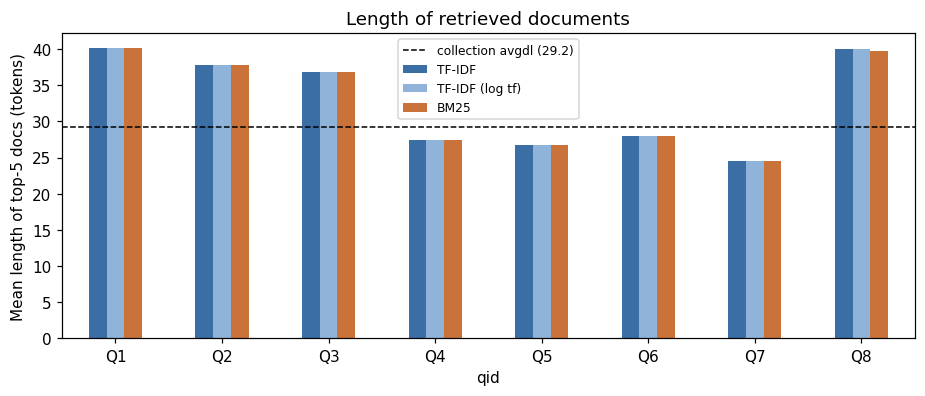

Rank of the long survey D28 (length 75 tokens) for each query ('-' = shares no word with the query):


qid,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8
TF-IDF,3,2,1,-,-,-,-,4
TF-IDF (log tf),3,2,1,-,-,-,-,4
BM25,3,2,1,-,-,-,-,4


In [19]:
def top5_len(model, q):
    ids, sc = ranking(model, q)
    keep = [np.where(docs.doc_id.values == d)[0][0] for d, s in zip(ids[:5], sc[:5]) if s > 0]
    return doc_len[keep].mean()

len_rows = {name: [top5_len(m, q) for q in queries["query"]] for name, m in SYSTEMS.items()}
len_df = pd.DataFrame(len_rows, index=queries.qid)
ax = len_df.plot(kind="bar", figsize=(10, 3.6), color=colors, rot=0)
ax.axhline(avgdl, color="black", ls="--", lw=1, label=f"collection avgdl ({avgdl:.1f})")
ax.set_ylabel("Mean length of top-5 docs (tokens)"); ax.legend(fontsize=8)
ax.set_title("Length of retrieved documents")
plt.show()
def rank_or_dash(model, q, did):
    ids, sc = ranking(model, q)
    r = int(np.where(ids == did)[0][0])
    return r + 1 if sc[r] > 0 else "-"

print("Rank of the long survey D28 (length", doc_len[27], "tokens) for each query ('-' = shares no word with the query):")
pd.DataFrame({name: [rank_or_dash(m, q, "D28") for q in queries["query"]]
              for name, m in SYSTEMS.items()}, index=queries.qid).T

### 9.4 How much do TF-IDF and BM25 agree?
- **Top-5 overlap:** how many documents the two top-5 lists share (only documents with a score above zero count).
- **Kendall's τ:** rank correlation over the documents that score above zero for at least one system (1 = identical order, 0 = unrelated, -1 = reversed). It is left blank when fewer than 3 documents match, because with 2 documents τ can only be +1 or -1.

In [20]:
agree = []
for _, r in queries.iterrows():
    a, b = tfidf.score(r["query"]), bm25.score(r["query"])
    mask = (a > 0) | (b > 0)
    tau = round(kendalltau(a[mask], b[mask])[0], 3) if mask.sum() >= 3 else ""
    top_a = {d for d, s in zip(*ranking(tfidf, r["query"])) if s > 0} & set(ranking(tfidf, r["query"])[0][:5])
    top_b = {d for d, s in zip(*ranking(bm25, r["query"])) if s > 0} & set(ranking(bm25, r["query"])[0][:5])
    agree.append({"qid": r.qid, "docs matched": int(mask.sum()), "top-5 overlap": len(top_a & top_b),
                  "Kendall tau": tau, "same #1": ranking(tfidf, r['query'])[0][0] == ranking(bm25, r['query'])[0][0]})
pd.DataFrame(agree).set_index("qid")

,docs matched,top-5 overlap,Kendall tau,same #1
qid,,,,
Q1,12,5,0.657,False
Q2,7,5,0.81,True
Q3,13,5,0.916,True
Q4,2,2,,True
Q5,6,5,0.867,True
Q6,3,3,0.333,False
Q7,2,2,,False
Q8,14,4,0.736,False


### 9.5 BM25 parameter study
MAP of BM25 as $k_1$ and $b$ change. $b=0$ switches length normalisation off; $k_1=0$ ignores term frequency altogether (every matching term counts once).

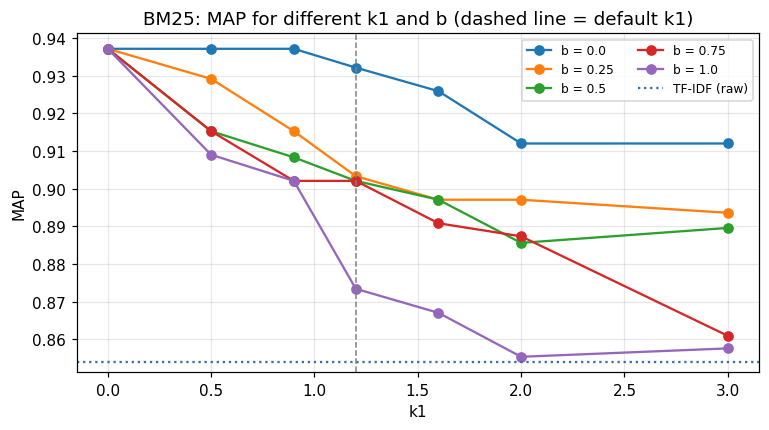

b,0.00,0.25,0.50,0.75,1.00
k1,,,,,
0.0,0.937,0.937,0.937,0.937,0.937
0.5,0.937,0.929,0.915,0.915,0.909
0.9,0.937,0.915,0.908,0.902,0.902
1.2,0.932,0.903,0.902,0.902,0.873
1.6,0.926,0.897,0.897,0.891,0.867
2.0,0.912,0.897,0.886,0.887,0.855
3.0,0.912,0.894,0.890,0.861,0.858


In [21]:
def map_score(model):
    return np.mean([average_precision(ranking(model, r["query"])[0], qrels[r.qid]) for _, r in queries.iterrows()])

k1_vals = [0.0, 0.5, 0.9, 1.2, 1.6, 2.0, 3.0]
b_vals = [0.0, 0.25, 0.5, 0.75, 1.0]
grid = pd.DataFrame([[map_score(BM25Ranker(index, doc_len, k1, b)) for b in b_vals] for k1 in k1_vals],
                    index=k1_vals, columns=b_vals)

plt.figure(figsize=(8, 4))
for b in b_vals:
    plt.plot(k1_vals, grid[b], "o-", label=f"b = {b}")
plt.axhline(summary.loc["TF-IDF", "MAP"], color="#3b6ea5", ls=":", label="TF-IDF (raw)")
plt.axvline(1.2, color="grey", ls="--", lw=1)
plt.xlabel("k1"); plt.ylabel("MAP"); plt.title("BM25: MAP for different k1 and b (dashed line = default k1)")
plt.legend(fontsize=8, ncol=2); plt.grid(alpha=0.3); plt.show()
grid.round(3).rename_axis(index="k1", columns="b")

### 9.6 Query speed
Thanks to the inverted index, scoring touches only the postings of the query terms.

In [22]:
for name, m in SYSTEMS.items():
    t0 = time.perf_counter()
    for _ in range(200):
        for q in queries["query"]:
            m.score(q)
    ms = (time.perf_counter() - t0) / (200 * len(queries)) * 1000
    print(f"{name:<16} {ms:.3f} ms per query")

TF-IDF           0.078 ms per query
TF-IDF (log tf)  0.067 ms per query
BM25             0.059 ms per query


## Step 10: Search interface
Type any query into `my_query` and run the cell. Results come from BM25 by default, and the matched words are highlighted in each snippet.

In [23]:
def search(query, k=3, system="BM25"):
    ids, sc = ranking(SYSTEMS[system], query)
    q_stems = set(preprocess(query))
    out = [f"<p><b>Query:</b> {html.escape(query)} &nbsp;|&nbsp; <b>System:</b> {system}</p>"]
    for r, (d, s) in enumerate(zip(ids[:k], sc[:k]), 1):
        if s <= 0:
            break
        row = docs.set_index("doc_id").loc[d]
        words = [f"<mark>{html.escape(w)}</mark>" if preprocess(w) and preprocess(w)[0] in q_stems else html.escape(w)
                 for w in row.text.split()]
        out.append(f"<p><b>#{r} [{d}] {html.escape(row.title)}</b> &nbsp;<small>score {s:.3f}</small><br>"
                   f"<span style='font-size:90%'>{' '.join(words[:45])} ...</span></p>")
    display(HTML("".join(out) if len(out) > 1 else out[0] + "<p>No matching documents.</p>"))

my_query = "removing noise from audio signals with filters"
search(my_query)

In [24]:
search("edge devices with low power", system="TF-IDF")

## Results and Observations
1. **Correctness of the implementations.** The from-scratch TF-IDF matches scikit-learn (difference about $10^{-17}$, for both raw and log tf), and the from-scratch BM25 matches `rank_bm25` (difference about $10^{-15}$), so the differences seen below come from the models themselves, not from bugs.
2. **The index and IDF.** After stemming, the collection has 501 distinct terms, and 73% of them occur in only one document. Common terms get a low weight and rare ones a high weight: *network* (in 11 documents) has a BM25 IDF of 0.99, while *optimiser* (in 2 documents) gets 2.52.
3. **Overall quality.** BM25 scored best on MAP (0.902), nDCG@10 (0.908) and MRR (1.0). Raw TF-IDF was lowest (0.854, 0.839 and 0.875), with log-tf TF-IDF in between (0.884, 0.900, 1.0). P@5 and R@5 are the same for all three (0.575 and 0.933), meaning the same documents reach the top 5 and the systems differ only in the order within it. P@5 cannot reach 1 here, since each query has only 2 to 5 relevant documents.
4. **Keyword stuffing.** Raw TF-IDF ranked the promotional page D27 **first** for both Q1 and Q8, which is the whole reason its MRR is 0.875 rather than 1. BM25 pushed D27 down to rank 5 (Q1) and rank 3 (Q8). The score breakdown shows why: *neural* and *network* each appear 10 times in D27, but saturation caps their contribution at 2.99 and 1.90. D05 wins because it matches the rare term *optimiser*, worth 3.31 on its own.
5. **Controlled repetition test.** Adding copies of *network* to D05 raised its raw TF-IDF score by 35% (0.377 to 0.509 at 11 copies) and its log-tf score by 25% (still rising at 40 copies). BM25 gained only 6% (peak at 4 copies) and then **fell below the original after about 18 copies**, because the length penalty keeps growing while the term-frequency gain has already saturated. Raw TF-IDF also drops after 11 copies, because cosine normalisation lets one term dominate the vector and weakens the match on the other query words. In BM25, repetition can only buy a small and limited gain.
6. **Shared failures: the limits of word matching.** For Q3 the key document D04 came only 5th in all three systems. The query word *prevent* does not occur anywhere in the collection (D04 says *remedies*), and D04 never says *deep learning*, while the reinforcement learning document D24 contains *deep* and *learns* and ranks 2nd. For Q2, Porter stemming reduces *sequence* to *sequenc* but *sequential* to *sequenti*, so the key document D02 misses that word. Neither TF-IDF nor BM25 can fix this. It needs query expansion, synonyms, or dense (embedding based) retrieval.
7. **Agreement between TF-IDF and BM25.** For queries that match many documents, Kendall's τ ranged from 0.66 to 0.92, and the top-5 lists overlapped almost completely. The top result was the same for 4 of the 8 queries. For Q6 and Q7 the only change was which of the two highly relevant documents came first, so the scores did not change. For Q1 and Q8 the difference is D27.
8. **Document length.** The long survey D28 (75 tokens, about 2.6 times the average) was placed at the same rank by all three systems, and the length chart shows no difference between methods. Documents in this collection are of similar length (34 to 110 words), so length normalisation would matter more in a collection where lengths vary widely.
9. **BM25 parameters.** Every setting in the grid scored a MAP of 0.855 or more, so at its worst BM25 matched raw TF-IDF (0.854) and otherwise beat it. The best setting here was $k_1 = 0$ (MAP 0.937), which ignores term frequency and simply adds the IDF of each matched term. It improves Q2, Q3 and Q8, most likely because most words in this short-document collection occur only once, so term frequency carries little information, and the main repetition is the spam page. Lower values of $b$ also did slightly better. With only 8 queries, picking $k_1$ and $b$ on the same queries used for evaluation would overfit, so the standard Lucene defaults ($k_1 = 1.2$, $b = 0.75$) are kept for the main results.
10. **Speed.** Thanks to the inverted index, each query took about 0.05 ms for both models, since only the postings of the query terms are read.

## Conclusion
TF-IDF and Okapi BM25 were implemented from scratch on top of an inverted index, checked against standard libraries, and used to rank a 30-document knowledge base for 8 queries with graded relevance labels. Both methods retrieved nearly the same set of relevant documents, but BM25 ordered them better (MAP 0.902 vs 0.854, nDCG@10 0.908 vs 0.839) and was far harder to fool with keyword stuffing, thanks to term-frequency saturation ($k_1$) and length normalisation ($b$). Sublinear (log) tf narrows the gap, which shows that damping repetition is the main advantage BM25 has here. Both models share the basic weakness of word matching: a relevant document that uses different words from the query cannot be found, which is the motivation for query expansion and semantic, embedding based retrieval.